In [3]:
!pip install -q tensorflow scikit-learn pandas matplotlib seaborn


In [4]:
import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [5]:
import os

print("CSV files available:")

for file in os.listdir("/content"):
    if file.endswith(".csv"):
        print(file)

CSV files available:
true.csv
fake.csv


In [8]:
import csv

# Load the available datasets using configurations that handle unclosed quotes or bad formatting
true_df = pd.read_csv("/content/true.csv", on_bad_lines='skip', engine='python')
fake_df = pd.read_csv("/content/fake.csv", on_bad_lines='skip', engine='python')

# Add target label: 1 for true, 0 for fake
true_df['label'] = 1
fake_df['label'] = 0

# Combine the datasets
df = pd.concat([true_df, fake_df], ignore_index=True)

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())

Dataset shape: (7550, 5)
Column names: ['title', 'text', 'subject', 'date', 'label']


,title,text,subject,date,label
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",1
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",1
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",1
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",1
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",1


In [10]:

# Handle missing values
df = df.dropna(subset=["text", "label"]).copy()

# Combine title and text
df["news_text"] = (
    df["title"].fillna("").astype(str) + " " +
    df["text"].fillna("").astype(str)
)

# Remove empty articles and duplicates
df["news_text"] = df["news_text"].str.strip()
df = df[df["news_text"] != ""]
df = df.drop_duplicates(subset=["news_text"])

# Select 1000 fake + 1000 real news articles
df["label"] = df["label"].astype(int)

df = (
    df.groupby("label", group_keys=False)
      .sample(n=1000, random_state=42)
      .reset_index(drop=True)
)

print("Dataset shape:", df.shape)
print(df["label"].value_counts())
display(df[["news_text", "label"]].head())


Dataset shape: (2000, 8)
label
0    1000
1    1000
Name: count, dtype: int64


,news_text,label
0,Trump Plans To Celebrate 100th Day On Office W...,0
1,Trump’s Rally Already Off The Rails As Nazis S...,0
2,GOP Just Demanded Hillary Clinton Give Them A ...,0
3,Pres. Obama Just Saved Chelsea Manning On His ...,0
4,Trump Gets His A** Handed To Him By British La...,0


In [11]:

import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["news_text"] = df["news_text"].apply(clean_text)

print(df[["news_text", "label"]].head())
print("Preprocessing completed!")


                                           news_text  label
0  trump plans to celebrate th day on office with...      0
1  trump s rally already off the rails as nazis s...      0
2  gop just demanded hillary clinton give them a ...      0
3  pres obama just saved chelsea manning on his w...      0
4  trump gets his a handed to him by british lawm...      0
Preprocessing completed!


In [12]:

from sklearn.model_selection import train_test_split

X = df["news_text"].values
y = df["label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 1600
Testing samples: 400


In [13]:

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_WORDS = 10000
MAX_LEN = 300

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)
print("Tokenization completed!")


Training shape: (1600, 300)
Testing shape: (400, 300)
Tokenization completed!


In [14]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

model = Sequential([
    tf.keras.Input(shape=(MAX_LEN,)),
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64, dropout=0.2),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,137 (2.58 MB)

 Trainable params: 675,137 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=8,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.5750 - loss: 0.6489 - val_accuracy: 0.9219 - val_loss: 0.4143
Epoch 2/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9273 - loss: 0.3091 - val_accuracy: 0.9312 - val_loss: 0.2489
Epoch 3/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9430 - loss: 0.2059 - val_accuracy: 0.9344 - val_loss: 0.2647
Epoch 4/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9500 - loss: 0.1958 - val_accuracy: 0.9344 - val_loss: 0.2587


In [16]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

y_prob = model.predict(X_test_pad).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0) * 100, 2), "%")
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0) * 100, 2), "%")
print("F1-score :", round(f1_score(y_test, y_pred, zero_division=0) * 100, 2), "%")


13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step
Accuracy : 91.75 %
Precision: 89.57 %
Recall   : 94.5 %
F1-score : 91.97 %


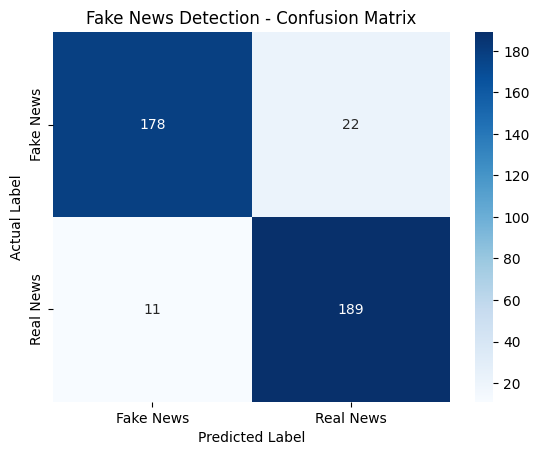

In [17]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake News", "Real News"],
    yticklabels=["Fake News", "Real News"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Fake News Detection - Confusion Matrix")
plt.show()


In [18]:

def predict_news(news):
    cleaned = clean_text(news)

    seq = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(
        seq,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    probability = float(
        model.predict(padded, verbose=0)[0][0]
    )

    if probability >= 0.5:
        print("Prediction: REAL NEWS")
    else:
        print("Prediction: FAKE NEWS")

    print("Real news score:", round(probability, 4))

predict_news(
    "The government announced a new education policy today."
)


Prediction: REAL NEWS
Real news score: 0.5845


In [19]:

model.save("/content/fake_news_lstm.keras")

import pickle

with open("/content/tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

print("Model and tokenizer saved successfully!")


Model and tokenizer saved successfully!
